# QNN — Bars and Stripes

Misma estructura que `QNN_Iris` (AngleEmbedding + BasicEntanglerLayers + Torch), sobre Bars and Stripes binario con PCA→4 qubits.


## Librerias


In [1]:
# 1. Import all libraries
import json
import time
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import pennylane as qml
from pennylane.data import Dataset
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


## Data

Imágenes oficiales PennyLane (`4×4` → 16 features). Carga lazy del `.h5`.


In [2]:
DATASET_URL = (
    "https://datasets.cloud.pennylane.ai/datasets/h5/"
    "other/BarsAndStripes/BarsAndStripes_BarsAndStripes.h5"
)
IMAGE_SIZE = "4"  # 4x4 pixels -> 16 features


def resolve_dataset_path() -> Path:
    """Busca el .h5 en caches locales tipicos de PennyLane."""
    candidates = []
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        candidates.append(
            base / "datasets" / "other" / "BarsAndStripes" / "BarsAndStripes_BarsAndStripes.h5"
        )
    for path in candidates:
        if path.is_file():
            return path
    return candidates[0]


def ensure_bars_and_stripes(path: Path | None = None) -> Path:
    path = resolve_dataset_path() if path is None else Path(path)
    if path.is_file():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading PennyLane bars-and-stripes -> {path} (one-time, ~750MB)")
    urllib.request.urlretrieve(DATASET_URL, path)
    return path


def load_bars_and_stripes(image_size: str = IMAGE_SIZE):
    path = ensure_bars_and_stripes()
    ds = Dataset.open(path, "r")
    try:
        X_train = np.asarray(ds.train[image_size]["inputs"], dtype=float)
        y_train = np.asarray(ds.train[image_size]["labels"], dtype=float)
        X_test = np.asarray(ds.test[image_size]["inputs"], dtype=float)
        y_test = np.asarray(ds.test[image_size]["labels"], dtype=float)
    finally:
        ds.close()
    return X_train, y_train, X_test, y_test


print("Loading PennyLane 'bars-and-stripes' (image_size=4)...")
X_train_official, y_train_official, X_test_official, y_test_official = load_bars_and_stripes(IMAGE_SIZE)
print(
    f"Official splits -> train: {X_train_official.shape}, test: {X_test_official.shape}"
)
print("Label values (train):", np.unique(y_train_official, return_counts=True))


Loading PennyLane 'bars-and-stripes' (image_size=4)...
Official splits -> train: (1000, 16), test: (200, 16)
Label values (train): (array([-1.,  1.]), array([514, 486]))


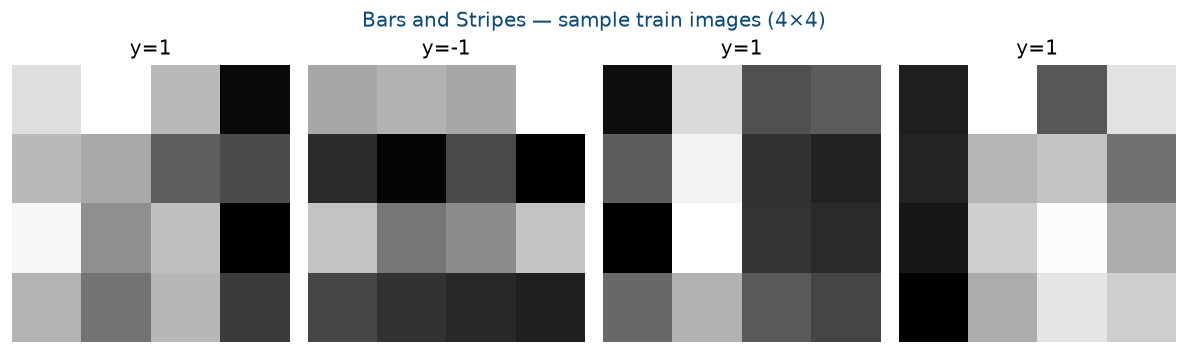

In [3]:
# Preview: first samples as 4x4 images + label
fig, axs = plt.subplots(1, 4, figsize=(10, 3), dpi=120)
for i, ax in enumerate(axs):
    ax.imshow(X_train_official[i].reshape(4, 4), cmap="gray")
    ax.set_title(f"y={int(y_train_official[i])}")
    ax.axis("off")
fig.suptitle("Bars and Stripes — sample train images (4×4)", color="#0E4A75")
plt.tight_layout()
plt.show()


## Data Preparation

Protocolo Iris + PCA→4 + tensores PyTorch.


In [4]:
# Dataset preparation
torch.manual_seed(123)
np.random.seed(123)

n_qubits = 4
n_classes = 2  # Bars and Stripes is binary

X = np.concatenate([X_train_official, X_test_official], axis=0)
y = np.concatenate([y_train_official, y_test_official], axis=0)
y = np.where(y <= 0, 0, 1).astype(int)

print(f"Combined dataset: n={len(X)}, features={X.shape[1]}, classes={np.unique(y, return_counts=True)}")

X_train_raw, X_test_raw, y_train_np, y_test_np = train_test_split(
    X, y, test_size=0.4, random_state=123, stratify=y
)

pca = PCA(n_components=n_qubits, random_state=123)
X_train_pca = pca.fit_transform(X_train_raw)
X_test_pca = pca.transform(X_test_raw)
print(f"PCA explained variance ratio sum: {pca.explained_variance_ratio_.sum():.4f}")

scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_scaled = scaler.fit_transform(X_train_pca)
X_test_scaled = np.clip(scaler.transform(X_test_pca), 0, np.pi)

X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)
y_test = torch.tensor(y_test_np, dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

n_features = n_qubits
print(f"Custom Dataset Loaded: Train={len(X_train)}, Test={len(X_test)}")
print(f"Final shapes -> Train: {tuple(X_train.shape)}, Test: {tuple(X_test.shape)}")


Combined dataset: n=1200, features=16, classes=(array([0, 1]), array([625, 575]))
PCA explained variance ratio sum: 0.5753
Custom Dataset Loaded: Train=720, Test=480
Final shapes -> Train: (720, 4), Test: (480, 4)


## Quantum Neural Network


In [5]:
# QNN model definition
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def qnode(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    qml.BasicEntanglerLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

n_layers = 6
weight_shapes = {"weights": (n_layers, n_qubits)}

class QNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.post = nn.Linear(n_qubits, n_classes)

    def forward(self, x):
        x = self.qlayer(x)
        return self.post(x)


## Entrenamiento QNN


In [6]:
# Generic training function
def train_model(model, loader, epochs=30, lr=0.01):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = []
    model.train()
    for epoch in range(epochs):
        epoch_loss = 0.0
        for bx, by in loader:
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        avg_loss = epoch_loss / len(loader)
        history.append(avg_loss)
        print(f"Epoch {epoch+1:2d} | Loss: {avg_loss:.4f}")
    return history


In [7]:
# Train QNN + timing
qnn_model = QNN()
start = time.time()
qnn_history = train_model(qnn_model, train_loader, epochs=30, lr=0.01)
qnn_time = time.time() - start
print(f"QNN training time: {qnn_time:.2f}s")


Epoch  1 | Loss: 0.7000
Epoch  2 | Loss: 0.6681
Epoch  3 | Loss: 0.6415
Epoch  4 | Loss: 0.6099
Epoch  5 | Loss: 0.5788
Epoch  6 | Loss: 0.5483
Epoch  7 | Loss: 0.5243
Epoch  8 | Loss: 0.5144
Epoch  9 | Loss: 0.5003
Epoch 10 | Loss: 0.4961
Epoch 11 | Loss: 0.4908
Epoch 12 | Loss: 0.4862
Epoch 13 | Loss: 0.4714
Epoch 14 | Loss: 0.4684
Epoch 15 | Loss: 0.4562
Epoch 16 | Loss: 0.4473
Epoch 17 | Loss: 0.4355
Epoch 18 | Loss: 0.4339
Epoch 19 | Loss: 0.4173
Epoch 20 | Loss: 0.4072
Epoch 21 | Loss: 0.4015
Epoch 22 | Loss: 0.3907
Epoch 23 | Loss: 0.3886
Epoch 24 | Loss: 0.3798
Epoch 25 | Loss: 0.3731
Epoch 26 | Loss: 0.3665
Epoch 27 | Loss: 0.3697
Epoch 28 | Loss: 0.3615
Epoch 29 | Loss: 0.3581
Epoch 30 | Loss: 0.3620
QNN training time: 4.83s


## Model Evaluation


In [8]:
@torch.no_grad()
def evaluate(model, X_t, y_t, classes):
    model.eval()
    logits = model(X_t)
    preds = torch.argmax(logits, dim=1).numpy()
    probs = nn.functional.softmax(logits, dim=1).numpy()

    y_true = y_t.numpy()
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, average="macro", zero_division=0)
    rec = recall_score(y_true, preds, average="macro", zero_division=0)
    f1 = f1_score(y_true, preds, average="macro", zero_division=0)
    if probs.shape[1] == 2:
        auc = roc_auc_score(y_true, probs[:, 1])
    else:
        auc = roc_auc_score(label_binarize(y_true, classes=classes), probs, average="macro")
    return acc, prec, rec, f1, auc, probs, preds

classes = np.unique(y_train_np)
qnn_acc, qnn_prec, qnn_rec, qnn_f1, qnn_auc, qnn_probs, qnn_preds = evaluate(
    qnn_model, X_test, y_test, classes
)
qnn_acc_tr, qnn_prec_tr, qnn_rec_tr, qnn_f1_tr, qnn_auc_tr, _, _ = evaluate(
    qnn_model, X_train, y_train, classes
)

print("\n=== Train vs Test ===")
print(
    f"QNN Train - Acc: {qnn_acc_tr:.4f} | Prec: {qnn_prec_tr:.4f} | Rec: {qnn_rec_tr:.4f} | "
    f"F1: {qnn_f1_tr:.4f} | AUC: {qnn_auc_tr:.4f}"
)
print(
    f"QNN Test  - Acc: {qnn_acc:.4f} | Prec: {qnn_prec:.4f} | Rec: {qnn_rec:.4f} | "
    f"F1: {qnn_f1:.4f} | AUC: {qnn_auc:.4f}"
)



=== Train vs Test ===
QNN Train - Acc: 0.8111 | Prec: 0.8167 | Rec: 0.8081 | F1: 0.8090 | AUC: 0.9346
QNN Test  - Acc: 0.8167 | Prec: 0.8201 | Rec: 0.8143 | F1: 0.8151 | AUC: 0.9357


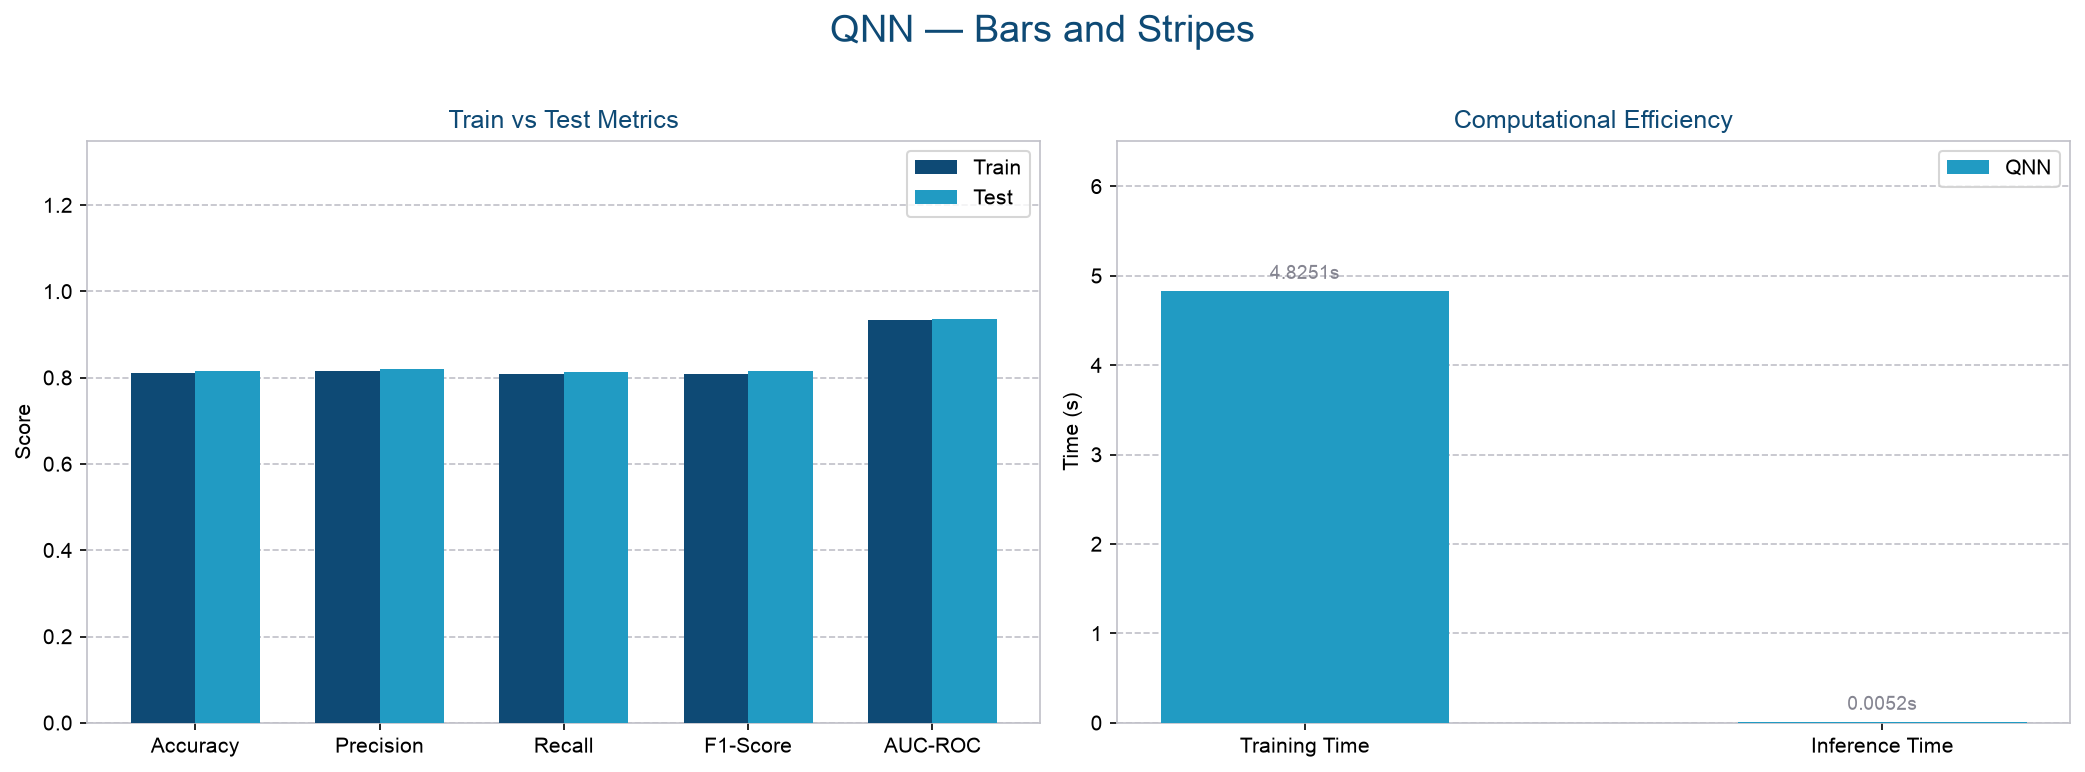

In [9]:
# Result Visualization (train vs test + paleta UNIR)
plt.rcParams.update({
    "font.sans-serif": ["Arial"],
    "axes.edgecolor": "#C0C0C8",
    "grid.color": "#C0C0C8",
    "grid.linestyle": "--",
})

@torch.no_grad()
def get_inference_time(model, data):
    start = time.time()
    _ = model(data)
    return time.time() - start

qnn_inf_time = get_inference_time(qnn_model, X_test)

train_color = "#0E4A75"
test_color = "#219BC3"
unir_gris = "#858591"

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle("QNN — Bars and Stripes", fontsize=18, y=1.02, color="#0E4A75")

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]
train_vals = [qnn_acc_tr, qnn_prec_tr, qnn_rec_tr, qnn_f1_tr, qnn_auc_tr]
test_vals = [qnn_acc, qnn_prec, qnn_rec, qnn_f1, qnn_auc]
x = np.arange(len(metrics))
width = 0.35

for i in range(len(metrics)):
    axs[0].bar(x[i] - width / 2, train_vals[i], width, color=train_color,
               label="Train" if i == 0 else "", zorder=3)
    axs[0].bar(x[i] + width / 2, test_vals[i], width, color=test_color,
               label="Test" if i == 0 else "", zorder=3)

axs[0].set_ylabel("Score")
axs[0].set_title("Train vs Test Metrics", color="#0E4A75")
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc="upper right")
axs[0].grid(axis="y", zorder=0)

eff_labels = ["Training Time", "Inference Time"]
qnn_eff = [qnn_time, qnn_inf_time]
x_eff = np.arange(len(eff_labels))
axs[1].bar(x_eff, qnn_eff, 0.5, color=test_color, label="QNN", zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel("Time (s)")
axs[1].set_title("Computational Efficiency", color="#0E4A75")
max_time = max(qnn_eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc="upper right")
axs[1].grid(axis="y", zorder=0)
offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], qnn_eff[i] + offset, f"{qnn_eff[i]:.4f}s",
                ha="center", va="bottom", fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()


## Guardar resultados


In [10]:
# Save metrics for BSClassification comparison
import json
from pathlib import Path
import sys

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "case_paths.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/case_paths.py not found")

import importlib
import case_paths as _case_paths
importlib.reload(_case_paths)
from case_paths import resolve_metrics_dir as _resolve_metrics_dir

def resolve_metrics_dir() -> Path:
    """Guarda en Notebooks/Classification/BSClassification/metrics (helper compartido)."""
    return _resolve_metrics_dir("Classification", "BSClassification")

metrics_dir = resolve_metrics_dir()



payload = {
    "model": "QNN",
    "family": "quantum",
    "protocol": {
        "dataset": "bars-and-stripes",
        "image_size": int(IMAGE_SIZE),
        "n_features": int(n_features),
        "test_size": 0.4,
        "random_state": 123,
        "stratify": True,
        "scaler": "MinMaxScaler[0, pi]",
        "labels": "mapped {-1,1}->{0,1}",
        "pca": "PCA(n_components=4)",
        "n_qubits": 4,
    },
    "train": {
        "accuracy": float(qnn_acc_tr),
        "precision": float(qnn_prec_tr),
        "recall": float(qnn_rec_tr),
        "f1": float(qnn_f1_tr),
        "auc": float(qnn_auc_tr),
    },
    "test": {
        "accuracy": float(qnn_acc),
        "precision": float(qnn_prec),
        "recall": float(qnn_rec),
        "f1": float(qnn_f1),
        "auc": float(qnn_auc),
    },
    "train_time_s": float(qnn_time),
    "inference_time_s": float(qnn_inf_time),
}

out = metrics_dir / "qnn_bs.json"
out.write_text(json.dumps(payload, indent=2))
print("Saved:", out)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/BSClassification/metrics/qnn_bs.json


## Storytelling plots

`figures/`: PCA sin frontera + con frontera del **mismo** modelo ya entrenado.
Puntos test usan `*_preds` del notebook; la malla usa `modelo.predict` (sin reentrenar).


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/BSClassification/figures/qnn_bs_samples.png


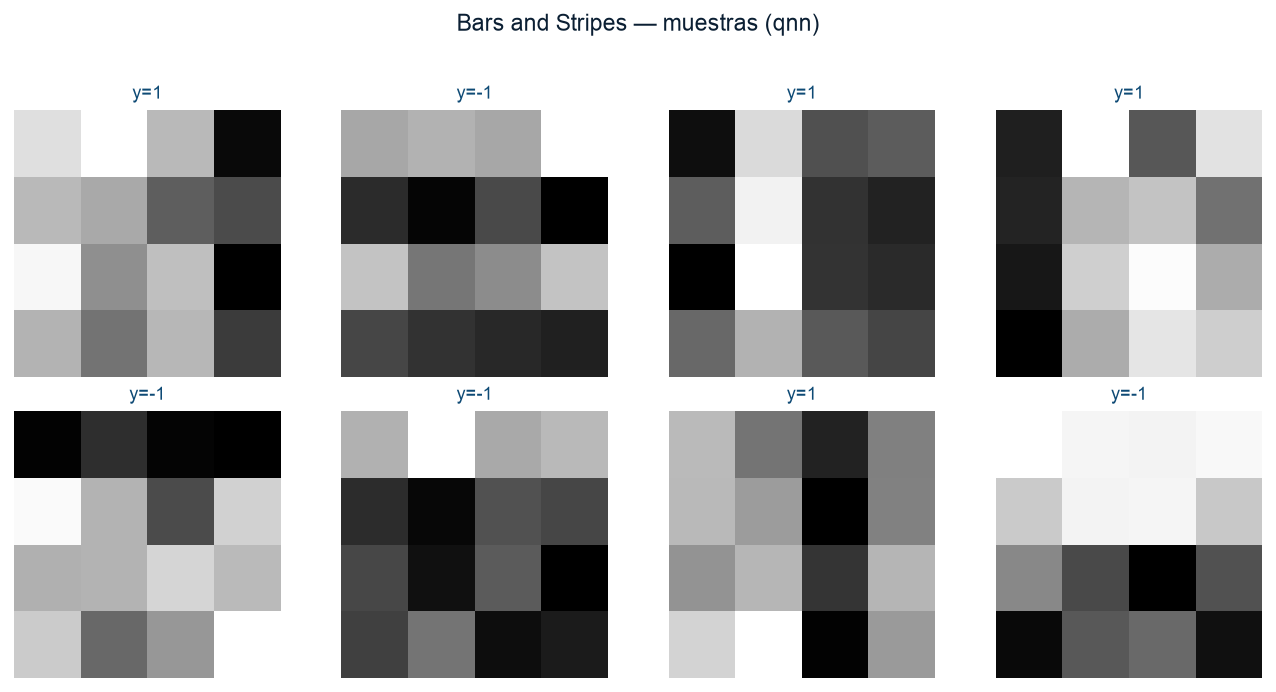

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/BSClassification/figures/qnn_bs_pca_scatter.png


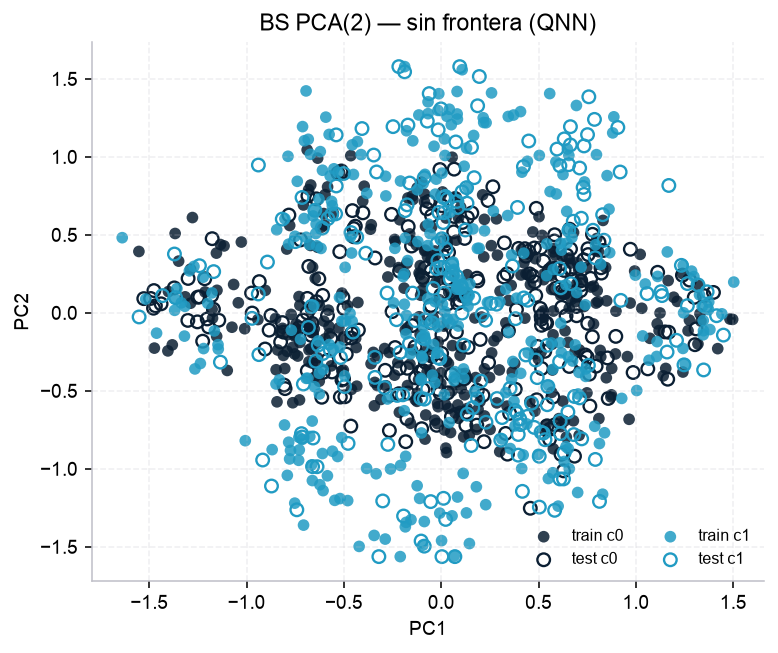

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/BSClassification/figures/qnn_bs_pca_boundary.png


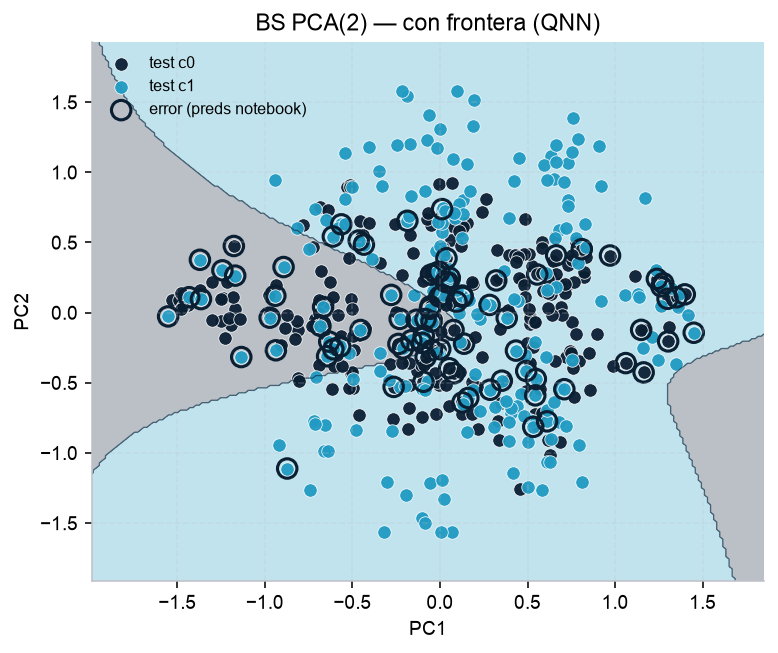

In [11]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import resolve_figures_dir, plot_bs_samples, plot_bs_pca_story

figures_dir = resolve_figures_dir("Classification", "BSClassification")
def _predict_fn(X):
    import torch
    qnn_model.eval()
    xt = torch.as_tensor(np.asarray(X, dtype=np.float32))
    with torch.no_grad():
        return torch.argmax(qnn_model(xt), dim=1).cpu().numpy()
predict_fn = _predict_fn
_imgs = X_train_official if "X_train_official" in globals() else (X_train_raw if "X_train_raw" in globals() else None)
_labs = y_train_official if "y_train_official" in globals() else y_train
if _imgs is not None:
    plot_bs_samples(_imgs, _labs, figures_dir, stem="qnn", n_show=8)
plot_bs_pca_story(
    X_train, y_train, X_test, y_test,
    y_pred_test=qnn_preds,
    predict_fn=predict_fn,
    figures_dir=figures_dir,
    stem="qnn",
    title_model="QNN",
)

plt.show()
